In [1]:
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import GroupKFold
from xgboost import XGBRegressor

DATA = "../data/raw/"
CAP, SEED = 125, 42

cols = (
    ["unit", "cycle"]
    + [f"op{i}" for i in range(1, 4)]
    + [f"s{i}" for i in range(1, 22)]
)

train = pd.read_csv(DATA + "train_FD001.txt", sep=r"\s+", header=None, names=cols)
test = pd.read_csv(DATA + "test_FD001.txt", sep=r"\s+", header=None, names=cols)
rul = pd.read_csv(DATA + "RUL_FD001.txt", header=None, names=["RUL"])

train["RUL"] = (train.groupby("unit")["cycle"].transform("max") - train["cycle"]).clip(upper=CAP)

sensor_cols = [c for c in cols if c.startswith("s")]
std = train[sensor_cols].std()
keep_sensors = [s for s in sensor_cols if std[s] >= 0.01]

y = train["RUL"]
groups = train["unit"]
y_test_true = np.minimum(rul["RUL"].values, CAP)

print(len(keep_sensors), "sensors kept")
print("shortest observed test engine:", test.groupby("unit")["cycle"].max().min(), "cycles")

14 sensors kept
shortest observed test engine: 31 cycles


In [2]:
def rmse(y_true, y_pred):
    return float(np.sqrt(np.mean((np.asarray(y_pred) - np.asarray(y_true)) ** 2)))

def nasa_score(y_true, y_pred):
    d = np.asarray(y_pred) - np.asarray(y_true)
    return float(np.sum(np.where(d < 0, np.exp(-d / 13) - 1, np.exp(d / 10) - 1)))

def make_model():
    return XGBRegressor(
        n_estimators=400, max_depth=5, learning_rate=0.05,
        subsample=0.8, colsample_bytree=0.8,
        random_state=SEED, n_jobs=-1,
    )

def slope_fn(x):
    # least-squares slope of the window against time (cycles)
    t = np.arange(len(x)) - (len(x) - 1) / 2
    return (t * (x - x.mean())).sum() / (t ** 2).sum()

def add_features(df, sensors, win, use_slope=False):
    out = df.copy()
    g = df.groupby("unit")
    for s in sensors:
        out[f"{s}_mean"] = g[s].transform(lambda x: x.rolling(win, min_periods=1).mean())
        out[f"{s}_std"] = g[s].transform(lambda x: x.rolling(win, min_periods=1).std()).fillna(0.0)
        if use_slope:
            out[f"{s}_slope"] = g[s].transform(
                lambda x: x.rolling(win, min_periods=2).apply(slope_fn, raw=True)
            ).fillna(0.0)
    return out

In [3]:
def run_experiment(win, use_slope):
    t0 = time.time()
    tr = add_features(train, keep_sensors, win, use_slope)
    te = add_features(test, keep_sensors, win, use_slope)

    feats = (
        keep_sensors
        + [f"{s}_mean" for s in keep_sensors]
        + [f"{s}_std" for s in keep_sensors]
        + ([f"{s}_slope" for s in keep_sensors] if use_slope else [])
    )
    X = tr[feats]

    cv = []
    for tr_idx, va_idx in GroupKFold(n_splits=5).split(X, y, groups):
        m = make_model().fit(X.iloc[tr_idx], y.iloc[tr_idx])
        cv.append(rmse(y.iloc[va_idx], m.predict(X.iloc[va_idx])))

    model = make_model().fit(X, y)
    last = te.groupby("unit").tail(1)
    preds = np.clip(model.predict(last[feats]), 0, CAP)

    return {
        "window": win,
        "slope": use_slope,
        "n_features": len(feats),
        "cv_rmse": np.mean(cv),
        "cv_std": np.std(cv),
        "test_rmse": rmse(y_test_true, preds),
        "nasa": nasa_score(y_test_true, preds),
        "secs": round(time.time() - t0, 1),
    }

In [4]:
results = []
for win in [5, 10, 20]:
    for use_slope in [False, True]:
        r = run_experiment(win, use_slope)
        results.append(r)
        print(r)

res = pd.DataFrame(results).sort_values("cv_rmse")
res.round(2)

{'window': 5, 'slope': False, 'n_features': 42, 'cv_rmse': np.float64(18.63331167962749), 'cv_std': np.float64(0.6027551240744043), 'test_rmse': 17.108253963201275, 'nasa': 727.6579901169505, 'secs': 177.9}
{'window': 5, 'slope': True, 'n_features': 56, 'cv_rmse': np.float64(18.41854098268808), 'cv_std': np.float64(0.5410126164316366), 'test_rmse': 17.258962947154025, 'nasa': 873.3322036014989, 'secs': 228.3}
{'window': 10, 'slope': False, 'n_features': 42, 'cv_rmse': np.float64(18.953657487850855), 'cv_std': np.float64(0.5929395284293687), 'test_rmse': 18.554963056057687, 'nasa': 1357.1338127514534, 'secs': 121.4}
{'window': 10, 'slope': True, 'n_features': 56, 'cv_rmse': np.float64(18.12077144297204), 'cv_std': np.float64(0.5335699996921126), 'test_rmse': 17.857189813375168, 'nasa': 919.156199777213, 'secs': 236.1}
{'window': 20, 'slope': False, 'n_features': 42, 'cv_rmse': np.float64(18.59470993119141), 'cv_std': np.float64(0.5401567000704297), 'test_rmse': 18.798785748346457, 'nasa

,window,slope,n_features,cv_rmse,cv_std,test_rmse,nasa,secs
5,20,True,56,15.52,0.60,15.57,443.20,234.4
3,10,True,56,18.12,0.53,17.86,919.16,236.1
1,5,True,56,18.42,0.54,17.26,873.33,228.3
4,20,False,42,18.59,0.54,18.80,1148.27,115.3
0,5,False,42,18.63,0.60,17.11,727.66,177.9
2,10,False,42,18.95,0.59,18.55,1357.13,121.4


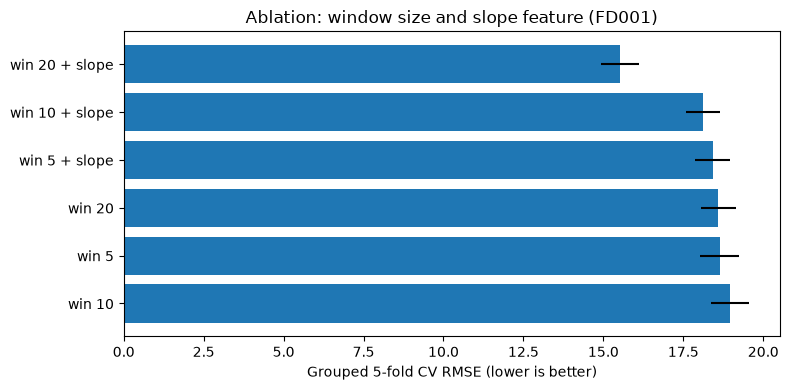

In [5]:
labels = [f"win {r.window}" + (" + slope" if r.slope else "") for r in res.itertuples()]
plt.figure(figsize=(8, 4))
plt.barh(labels[::-1], res["cv_rmse"].values[::-1], xerr=res["cv_std"].values[::-1])
plt.xlabel("Grouped 5-fold CV RMSE (lower is better)")
plt.title("Ablation: window size and slope feature (FD001)")
plt.tight_layout()
plt.show()

## Ablation study: window size and slope feature (FD001)

Same model, same 5 grouped CV folds, same seed. Only the features change. Median baseline test RMSE: 49.20.

| Window | Slope | Features | CV RMSE | CV std | Test RMSE | NASA score |
|---|---|---|---|---|---|---|
| 20 | yes | 56 | 15.52 | 0.60 | 15.57 | 443.20 |
| 10 | yes | 56 | 18.12 | 0.53 | 17.86 | 919.16 |
| 5 | yes | 56 | 18.42 | 0.54 | 17.26 | 873.33 |
| 20 | no | 42 | 18.59 | 0.54 | 18.80 | 1148.27 |
| 5 | no | 42 | 18.63 | 0.60 | 17.11 | 727.66 |
| 10 | no | 42 | 18.95 | 0.59 | 18.55 | 1357.13 |

**Findings**
- The Day 4 baseline (window 10, no slope) is reproduced exactly: test RMSE 18.55 and NASA score 1357. This confirms the pipeline is consistent.
- Window size alone does not help. Without the slope feature, CV RMSE is 18.63, 18.95 and 18.59 for windows 5, 10 and 20. These differences are smaller than the fold-to-fold standard deviation (about 0.6), so they are effectively tied.
- The slope feature helps, but only clearly at window 20. At window 5 it improves CV RMSE by about 0.2 (within noise), at window 10 by about 0.8, and at window 20 by about 3.1 (18.59 to 15.52).
- Window 20 with slope is the best configuration: CV RMSE 15.52, about 2.6 lower than the next best (18.12). That gap is more than four times the CV standard deviation, so it is a real improvement.
- A likely reason is that the sensors are very noisy (seen in the EDA plots). The trend over 5 or 10 cycles is mostly noise, while over 20 cycles the slope captures the real degradation direction. I have not tested this explanation directly.
- On the test set, the best configuration reaches RMSE 15.57 and NASA score 443, compared with 49.20 for the median baseline and 18.55 / 1357 for the Day 4 baseline. That is about a 16% lower RMSE and 67% lower NASA score than the Day 4 baseline.
- Test RMSE is not perfectly aligned with CV. For example, window 5 without slope has a better test RMSE (17.11) than window 10 (18.55) despite a similar CV score. The test set has only 100 engines, so its score is noisy. I therefore chose the configuration by CV, not by test score.
- The slope runs cost more compute (about 230 s vs 115-180 s per experiment), but the gain justifies it.
- **Chosen configuration for later models: window 20 + slope (56 features).**
- Next steps: test longer windows (30; the shortest test engine has 31 cycles), then move to sequence models (GRU/LSTM) and compare them against this baseline.

In [6]:
r30 = run_experiment(30, True)
print(r30)

{'window': 30, 'slope': True, 'n_features': 56, 'cv_rmse': np.float64(13.19529395745531), 'cv_std': np.float64(0.5593816607552016), 'test_rmse': 13.111420054979888, 'nasa': 257.08004533652206, 'secs': 233.7}


In [7]:
print({k: (round(float(v), 2) if not isinstance(v, (bool, int)) else v) for k, v in r30.items()})

{'window': 30, 'slope': True, 'n_features': 56, 'cv_rmse': 13.2, 'cv_std': 0.56, 'test_rmse': 13.11, 'nasa': 257.08, 'secs': 233.7}


   | 30 | yes | 56 | 13.20 | 0.56 | 13.11 |257.08 |

- A longer window kept helping the slope features: CV RMSE with slope was 18.42 (window 5), 18.12 (window 10), 15.52 (window 20) and 13.20 (window 30). The window 30 gain over window 20 is about 2.3, more than four times the CV standard deviation (0.56), so it is a real improvement.
- Window 30 + slope reaches test RMSE of about 13.11, compared with 49.20 for the median baseline and 18.55 for the Day 4 baseline (about 29% lower RMSE than Day 4).
- **Chosen configuration for later models: window 30 + slope (56 features).**
- Window 30 is the longest window that fits every FD001 test engine without padding, because the shortest test engine has 31 observed cycles. I stopped here rather than test longer windows, which would need special handling for the short engines.
- Next steps: set up experiment tracking (MLflow), then build sequence models (GRU/LSTM) that read raw sensor windows directly. I will compare them against this XGBoost result (CV RMSE 13.20, test RMSE about 13.11).